In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import requests

In [2]:
url = "https://official-joke-api.appspot.com/jokes/random"
response = requests.get(url)
print(response)

<Response [200]>


In [3]:
data = response.json()
print(data)

{'type': 'general', 'setup': 'What did the fish say when it hit the wall?', 'punchline': 'Dam.', 'id': 1}


In [4]:
print(f"Here's a random joke for you: {data['setup']} - {data['punchline']}")

Here's a random joke for you: What did the fish say when it hit the wall? - Dam.


Miniproject

In [5]:
import urllib.request
import urllib.parse
import json
import time

In [6]:
url = "https://geocoding-api.open-meteo.com/v1/search"
params = {"name": "Dresden",
        "count": 5,
        "language": "en",
        "format": "json"}
query_string = urllib.parse.urlencode(params)
new_url = url + "?" + query_string
print(new_url)

https://geocoding-api.open-meteo.com/v1/search?name=Dresden&count=5&language=en&format=json


In [7]:
start_time = time.perf_counter()
with urllib.request.urlopen(new_url, timeout=10) as response:
    status_code = response.status
    print(f"HTTP Status Code: {status_code}")
    content_type = response.getheader('Content-Type')
    print(f"Content-Type: {content_type}")
    data = json.loads(response.read().decode("utf-8"))
end_time = time.perf_counter()
response_time= end_time - start_time
print(f"Response Time: {response_time:.3f} seconds")
if 'results' in data and data['results']:
    new_data = data['results'][0]
    json_data = json.dumps(new_data, indent=4)
    print(json_data)
else:
    print("No results found for the specified location.")


HTTP Status Code: 200
Content-Type: application/json; charset=utf-8
Response Time: 1.405 seconds
{
    "id": 2935022,
    "name": "Dresden",
    "latitude": 51.05089,
    "longitude": 13.73832,
    "elevation": 116.0,
    "feature_code": "PPLA",
    "country_code": "DE",
    "admin1_id": 2842566,
    "admin3_id": 2935020,
    "admin4_id": 6551127,
    "timezone": "Europe/Berlin",
    "population": 556227,
    "country_id": 2921044,
    "country": "Germany",
    "admin1": "Saxony",
    "admin3": "Kreisfreie Stadt Dresden",
    "admin4": "Dresden"
}


In [8]:
start_time = time.perf_counter()
response = requests.get(url, params=params, timeout=10)
response.raise_for_status()  # Raise an exception for HTTP errors
print(f"HTTP Status Code: {response.status_code}")
content_type = response.headers.get('Content-Type')
print(f"Content-Type: {content_type}")
json_data = response.json()
end_time = time.perf_counter()
response_time= end_time - start_time
print(f"Response Time: {response_time:.3f} seconds")
if 'results' in json_data and json_data['results']:
    new_data = json_data['results'][0]
    formatted_json = json.dumps(new_data, indent=4)
    print(formatted_json)
else:
    print("No results found for the specified location.")    

HTTP Status Code: 200
Content-Type: application/json; charset=utf-8
Response Time: 1.355 seconds
{
    "id": 2935022,
    "name": "Dresden",
    "latitude": 51.05089,
    "longitude": 13.73832,
    "elevation": 116.0,
    "feature_code": "PPLA",
    "country_code": "DE",
    "admin1_id": 2842566,
    "admin3_id": 2935020,
    "admin4_id": 6551127,
    "timezone": "Europe/Berlin",
    "population": 556227,
    "country_id": 2921044,
    "country": "Germany",
    "admin1": "Saxony",
    "admin3": "Kreisfreie Stadt Dresden",
    "admin4": "Dresden"
}


Code length and readability: The requests library requires less code to perform common API operations. It provides convenient methods such as requests.get(), response.json(), and the params argument for passing query parameters. In contrast, urllib.request often requires additional steps, such as constructing the query string with urllib.parse.urlencode(), decoding response bytes, and parsing JSON using json.loads(). Therefore, requests is generally easier to read and use when working with APIs.

Error handling: With urllib.request, HTTP errors such as 404 Not Found can raise an urllib.error.HTTPError, while connection problems may raise urllib.error.URLError. With requests, connection and timeout errors can be handled using exceptions such as requests.ConnectionError and requests.Timeout. The method response.raise_for_status() also provides a convenient way to raise an exception for unsuccessful HTTP status codes. 

Header and encoding control: With urllib.request, headers can be supplied through a urllib.request.Request object, while response headers can be accessed using methods such as response.getheader(). With requests, headers can be passed directly through the headers argument, and response headers can be accessed using response.headers. 

Both libraries are suitable for accessing web APIs. However, requests is generally more convenient and readable for everyday API development because it simplifies query parameters, JSON processing, and HTTP error handling. urllib.request remains useful when working with Python's standard library without installing an additional package. 

I sent a GET request to the Open-Meteo Geocoding API using the requests library. The request returned an HTTP status code of 200, indicating that it was successful. The Content-Type header was application/json; charset=utf-8, showing that the response was returned in JSON format. The measured response time was 1.011 seconds using requests, compared with 1.230 seconds using urllib.request. This measurement represents the time taken to send the request and receive the HTTP response. 

In [9]:
geocoding_url = "https://geocoding-api.open-meteo.com/v1/search"
location = 'Kampala'
params = {"name": location,
          "count": 5,       
          "language": "en",
          "format": "json"}
response = requests.get(geocoding_url, params=params, timeout=10)
response.raise_for_status()  # Raise an exception for HTTP errors
response_data = response.json()
if 'results' in response_data and response_data['results']:
    for result in response_data['results']:
        print(f"Name: {result['name']}, Country: {result['country']}, Latitude: {result['latitude']}, Longitude: {result['longitude']}")
else:
    print("No results found for the specified location.")    

Name: Kampala, Country: Uganda, Latitude: 0.31628, Longitude: 32.58219
Name: Kampala, Country: Ivory Coast, Latitude: 7.32344, Longitude: -7.68519
Name: Kampala, Country: Democratic Republic of Congo, Latitude: 2.30086, Longitude: 30.59269
Name: Kampala, Country: Democratic Republic of Congo, Latitude: -2.19509, Longitude: 27.74864
Name: Kampala, Country: Zambia, Latitude: -14.41129, Longitude: 31.6098


In [10]:
selected_place = response_data['results'][0]

latitude = selected_place['latitude']
longitude = selected_place['longitude']

print("Selected location:", selected_place['name'])
print("Latitude:", latitude)
print("Longitude:", longitude)

Selected location: Kampala
Latitude: 0.31628
Longitude: 32.58219


In [11]:
forecast_url = "https://api.open-meteo.com/v1/forecast"
forecast_params = {
    "latitude": latitude,
    "longitude": longitude
}
daily_forecast = ["temperature_2m_max", "temperature_2m_min", "precipitation_sum", "windspeed_10m_max", "weather_code"]
timezone = "auto"
forecast_request = requests.get(forecast_url, params={**forecast_params, "daily": ",".join(daily_forecast), "timezone": timezone}, timeout=10)
forecast_request.raise_for_status()  
forecast_data = forecast_request.json()
weather_codes = {
    0: "Clear sky",1: "Mainly clear",2: "Partly cloudy",3: "Overcast",
    45: "Fog",48: "Depositing rime fog",51: "Light drizzle",53: "Moderate drizzle",
    55: "Dense drizzle", 56: "Light freezing drizzle",57: "Dense freezing drizzle",
    61: "Slight rain",63: "Moderate rain",65: "Heavy rain", 66: "Light freezing rain", 67: "Heavy freezing rain",
    71: "Slight snow fall",73: "Moderate snow fall",75: "Heavy snow fall",77: "Snow grains",
    80: "Slight rain showers",81: "Moderate rain showers",82: "Violent rain showers",
    85: "Slight snow showers",86: "Heavy snow showers",
    95: "Thunderstorm",96: "Thunderstorm with slight hail",99: "Thunderstorm with heavy hail"
}
forecast_df = pd.DataFrame({
    "Date": forecast_data["daily"]["time"],
    "Max Temperature (°C)": forecast_data["daily"]["temperature_2m_max"],
    "Min Temperature (°C)": forecast_data["daily"]["temperature_2m_min"],
    "Precipitation (mm)": forecast_data["daily"]["precipitation_sum"],
    "Max Wind Speed (km/h)": forecast_data["daily"]["windspeed_10m_max"],
    "Weather Code": forecast_data["daily"]["weather_code"],
    "Weather Description": [weather_codes.get(code, "Unknown") for code in forecast_data["daily"]["weather_code"]]
})
print(forecast_df)

         Date  Max Temperature (°C)  Min Temperature (°C)  Precipitation (mm)  \
0  2026-10-13                  26.8                  18.2                 4.3   
1  2026-10-14                  28.0                  19.2                 2.7   
2  2026-10-15                  26.7                  19.2                 1.1   
3  2026-10-16                  25.3                  18.6                17.6   
4  2026-10-17                  25.0                  18.8                 9.9   
5  2026-10-18                  25.4                  18.7                 4.2   
6  2026-10-19                  26.0                  17.9                 8.1   

   Max Wind Speed (km/h)  Weather Code    Weather Description  
0                   11.2            80    Slight rain showers  
1                    9.3            53       Moderate drizzle  
2                   10.2            51          Light drizzle  
3                   15.1            95           Thunderstorm  
4                   10.0       

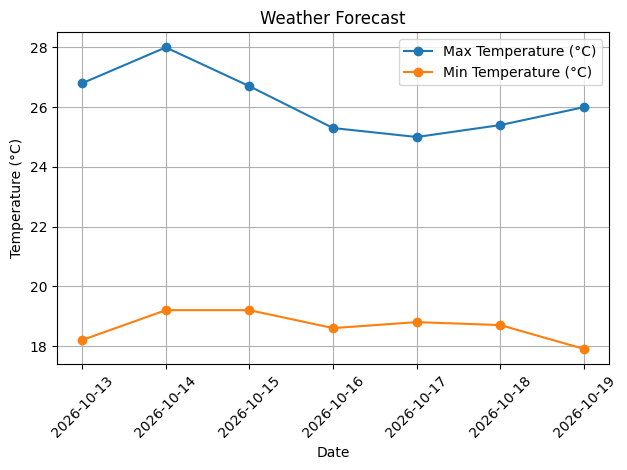

In [12]:
chart = forecast_df.plot(x="Date", y=["Max Temperature (°C)", "Min Temperature (°C)"], kind="line", marker="o")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Weather Forecast")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
display(forecast_df.round(2))

,Date,Max Temperature (°C),Min Temperature (°C),Precipitation (mm),Max Wind Speed (km/h),Weather Code,Weather Description
0,2026-10-13,26.8,18.2,4.3,11.2,80,Slight rain showers
1,2026-10-14,28.0,19.2,2.7,9.3,53,Moderate drizzle
2,2026-10-15,26.7,19.2,1.1,10.2,51,Light drizzle
3,2026-10-16,25.3,18.6,17.6,15.1,95,Thunderstorm
4,2026-10-17,25.0,18.8,9.9,10.0,81,Moderate rain showers
5,2026-10-18,25.4,18.7,4.2,8.0,55,Dense drizzle
6,2026-10-19,26.0,17.9,8.1,8.6,53,Moderate drizzle


In [14]:

from src.weather_api import get_weather_with_retry, WeatherAPIError


In [15]:
forecast_url = "https://api.open-meteo.com/v1/forecast"

forecast_params = {
    "latitude": latitude,
    "longitude": longitude,
    "daily": "temperature_2m_max,temperature_2m_min",
    "timezone": "auto"
}

try:
    forecast_data = get_weather_with_retry(
        forecast_url,
        params=forecast_params
    )

    print("Forecast retrieved successfully!")
    print(forecast_data)

except WeatherAPIError as error:
    print("Error:", error)

Forecast retrieved successfully!
{'latitude': 0.31634447, 'longitude': 32.554688, 'generationtime_ms': 1.3920068740844727, 'utc_offset_seconds': 10800, 'timezone': 'Africa/Kampala', 'timezone_abbreviation': 'GMT+3', 'elevation': 1224.0, 'daily_units': {'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C'}, 'daily': {'time': ['2026-10-13', '2026-10-14', '2026-10-15', '2026-10-16', '2026-10-17', '2026-10-18', '2026-10-19'], 'temperature_2m_max': [26.8, 28.0, 26.7, 25.3, 25.0, 25.4, 26.0], 'temperature_2m_min': [18.2, 19.2, 19.2, 18.6, 18.8, 18.7, 17.9]}}


In [16]:
forecast_url = "https://api.open-meteo.com/v1/forecast"

try:
    result = get_weather_with_retry(
        forecast_url,
        params={
            "latitude": 150,
            "longitude": 32.58,
            "daily": "temperature_2m_max",
            "timezone": "auto"
        },
        timeout=10
    )

    print("API returned a response:", result)

except WeatherAPIError as error:
    print("Invalid latitude test:", error)

Invalid latitude test: Weather API returned HTTP 400: 400 Client Error: Bad Request for url: https://api.open-meteo.com/v1/forecast?latitude=150&longitude=32.58&daily=temperature_2m_max&timezone=auto


In [17]:
try:
    get_weather_with_retry(
        "http://192.0.2.1/",
        timeout=2,
        max_retries=3
    )

except WeatherAPIError as error:
    print("Simulated network failure:", error)

Attempt 1 failed. Retrying in 1 seconds...
Attempt 2 failed. Retrying in 2 seconds...
Simulated network failure: Weather request failed after 3 attempts. Last error: HTTPConnectionPool(host='192.0.2.1', port=80): Max retries exceeded with url: / (Caused by ConnectTimeoutError(<HTTPConnection(host='192.0.2.1', port=80) at 0x2e148d28550>, 'Connection to 192.0.2.1 timed out. (connect timeout=2)'))


In [18]:
try:
    get_weather_with_retry(
        forecast_url,
        params={
            "latitude": latitude,
            "longitude": longitude,
            "daily": "temperature_2m_max",
            "timezone": "auto"
        },
        timeout=0.000001,
        max_retries=3
    )

except WeatherAPIError as error:
    print("Tiny-timeout test:", error)

Attempt 1 failed. Retrying in 1 seconds...
Attempt 2 failed. Retrying in 2 seconds...
Tiny-timeout test: Weather request failed after 3 attempts. Last error: HTTPSConnectionPool(host='api.open-meteo.com', port=443): Max retries exceeded with url: /v1/forecast?latitude=0.31628&longitude=32.58219&daily=temperature_2m_max&timezone=auto (Caused by ConnectTimeoutError(<HTTPSConnection(host='api.open-meteo.com', port=443) at 0x2e148d28e10>, 'Connection to api.open-meteo.com timed out. (connect timeout=1e-06)'))


In [19]:
geocoding_url = "https://geocoding-api.open-meteo.com/v1/search"

try:
    result = get_weather_with_retry(
        geocoding_url,
        params={"name": "InvalidCityXYZ999", "count": 5},
        timeout=10
    )

    if not result.get("results"):
        print("Test passed: No matching city was found.")
    else:
        print("Location found:", result["results"][0]["name"])

except WeatherAPIError as error:
    print("Request failed:", error)

Test passed: No matching city was found.


In [20]:
original_get = requests.get

class MockResponse:
    status_code = 503

    def raise_for_status(self):
        raise requests.exceptions.HTTPError(
            "503 Server Error: Service Unavailable",
            response=self
        )

def mock_get(*args, **kwargs):
    return MockResponse()

requests.get = mock_get

try:
    get_weather_with_retry(
        "https://example.com/weather",
        timeout=10,
        max_retries=3
    )

except WeatherAPIError as error:
    print("5xx test:", error)

finally:
    requests.get = original_get

Attempt 1 failed. Retrying in 1 seconds...
Attempt 2 failed. Retrying in 2 seconds...
5xx test: Weather request failed after 3 attempts. Last error: 503 Server Error: Service Unavailable


Using a second source

In [21]:
met_url = "https://api.met.no/weatherapi/locationforecast/2.0/compact"
met_params = {
    "lat": latitude,
    "lon": longitude
}
headers = {
    "User-Agent": "StudentWeatherForecast/1.0 b38634@students.ucu.ac.ug"
}


In [22]:
try:
    met_data = get_weather_with_retry(
        met_url,
        params=met_params,
        headers=headers,
        timeout=10,
        max_retries=3
    )

    print("MET Norway forecast retrieved successfully!")
    print("Top-level keys:", met_data.keys())

except WeatherAPIError as error:
    print("MET Norway request failed:", error)


MET Norway forecast retrieved successfully!
Top-level keys: dict_keys(['type', 'geometry', 'properties'])


In [23]:
print(met_data["properties"]["timeseries"][0])

{'time': '2026-10-13T18:00:00Z', 'data': {'instant': {'details': {'air_pressure_at_sea_level': 1013.4, 'air_temperature': 21.1, 'cloud_area_fraction': 86.7, 'relative_humidity': 90.2, 'wind_from_direction': 311.4, 'wind_speed': 3.1}}, 'next_12_hours': {'summary': {'symbol_code': 'partlycloudy_night'}, 'details': {}}, 'next_1_hours': {'summary': {'symbol_code': 'cloudy'}, 'details': {'precipitation_amount': 0.0}}, 'next_6_hours': {'summary': {'symbol_code': 'cloudy'}, 'details': {'precipitation_amount': 0.0}}}}


In [24]:
forecast_entry = met_data["properties"]["timeseries"][0]

instant = forecast_entry["data"]["instant"]["details"]
next_1_hour = forecast_entry["data"].get("next_1_hours", {})
next_6_hours = forecast_entry["data"].get("next_6_hours", {})
next_12_hours = forecast_entry["data"].get("next_12_hours", {})

met_df = pd.DataFrame([{
    "Forecast Time (UTC)": forecast_entry["time"],
    "Temperature (°C)": instant.get("air_temperature"),
    "Relative Humidity (%)": instant.get("relative_humidity"),
    "Wind Speed (m/s)": instant.get("wind_speed"),
    "Cloud Cover (%)": instant.get("cloud_area_fraction"),
    "Pressure (hPa)": instant.get("air_pressure_at_sea_level"),
    "Next 1-Hour Precipitation (mm)": next_1_hour.get("details", {}).get("precipitation_amount"),
    "Next 6-Hour Precipitation (mm)": next_6_hours.get("details", {}).get("precipitation_amount"),
    "Next 12-Hour Weather": next_12_hours.get("summary", {}).get("symbol_code")
}])

display(met_df.round(2))


,Forecast Time (UTC),Temperature (°C),Relative Humidity (%),Wind Speed (m/s),Cloud Cover (%),Pressure (hPa),Next 1-Hour Precipitation (mm),Next 6-Hour Precipitation (mm),Next 12-Hour Weather
0,2026-10-13T18:00:00Z,21.1,90.2,3.1,86.7,1013.4,0.0,0.0,partlycloudy_night


Report on the Weather Forecast Application

This project involved developing a Python weather forecast application that retrieves weather information from online APIs, processes the returned JSON data, and displays the results in a readable format. The application uses Open-Meteo as its primary source and MET Norway as a second source. Python libraries, including `requests`, `json`, `pandas`, and `matplotlib`, were used to support communication with the APIs, data processing, and visualisation.

The application uses Kampala, Uganda, as an example location. It retrieves geographical coordinates, requests daily weather forecasts, converts the returned data into a pandas DataFrame, and presents information such as maximum and minimum temperatures, precipitation, wind speed, and weather descriptions. The application also implements error handling and retry mechanisms to improve reliability. This report describes the data flow, API licensing and usage terms, reliability challenges, and privacy implications.

Data Flow from User Input to Displayed Forecast

The application follows a sequence of steps that transforms a location query into a displayed weather forecast.

First, the user specifies a location, such as Kampala. The application sends this location to the Open-Meteo Geocoding API, which searches for matching places and returns information such as the place name, latitude, and longitude. Where several matches are returned, the application can display the alternatives and select the appropriate location.

Second, the application sends the selected coordinates to the Open-Meteo Forecast API. The request specifies the required weather variables and the local time zone. The API returns a JSON response containing daily forecast information. The application converts this response into a Python dictionary using the `response.json()` method.

Third, the application extracts the required variables and places them into a pandas DataFrame.Numerical weather codes are then translated into readable descriptions using a dictionary based on the WMO weather interpretation codes documented by Open-Meteo. Finally, the application displays the forecast in a formatted table and uses Matplotlib to plot the temperature range alongside precipitation.

The MET Norway API provides an alternative source of weather information. Its response has a different structure, so the application extracts the relevant values from the nested JSON response.
The overall data flow is illustrated below:
User enters location
        |
Open-Meteo Geocoding API
        |
Latitude and longitude
        |
Open-Meteo Forecast API
        |
JSON response
        |
Python dictionary and data extraction
        |
pandas DataFrame and weather-code mapping
        |
Formatted table, summary and chart

This design separates data retrieval from data processing and presentation. Consequently, the application can process information from different providers while presenting it in a consistent format.

#Licensing and Usage Terms of the APIs
Open-Meteo provides geocoding and weather forecast services through HTTP APIs. Its published terms allow free API use for non-commercial purposes, subject to usage limits and fair-use requirements. The free service has limits of fewer than 10,000 API calls per day, 5,000 per hour, and 600 per minute. Applications intended for commercial use should arrange the appropriate commercial access with Open-Meteo. The service also states that forecast data are provided without a warranty of accuracy, completeness, or uninterrupted availability.

Sources: [Open-Meteo Terms of Use](https://open-meteo.com/en/terms) and [Open-Meteo Pricing](https://open-meteo.com/en/pricing).

The weather data are licensed under Creative Commons Attribution 4.0 International (CC BY 4.0). This licence generally permits the reuse, adaptation, and redistribution of the data, including for commercial purposes, provided that the required attribution is given. Users should credit Open-Meteo and its underlying data sources where appropriate, link to the licence, and indicate whether changes have been made.

MET Norway's Locationforecast API provides forecast information for locations worldwide. Its published licensing policy states that, unless otherwise specified, data and products are available under the Norwegian Licence for Open Government Data (NLOD) 2.0 and Creative Commons Attribution 4.0 International licences. Users must credit the Norwegian Meteorological Institute, commonly referred to as MET Norway, as the source. Suitable wording includes “Data from MET Norway” or “Based on data from MET Norway.” Users should also link to the source and relevant licence and indicate changes where applicable.

Sources: [MET Norway Licensing and Data Policy](https://docs.api.met.no/doc/License.html) and [MET Norway Terms of Service](https://api.met.no/doc/TermsOfService).

MET Norway also imposes service-specific requirements. Requests should contain an identifying `User-Agent` header with the application's name and contact information, such as an email address. Users should avoid unnecessary requests, respect caching guidance, and avoid overloading the service. Excessive traffic or failure to identify an application can result in throttling or blocking. MET Norway also states that it does not guarantee service delivery or provide a service-level agreement for this public API. For a real product, these conditions mean that the developer must include appropriate attribution, identify the application correctly, manage request frequency, and plan for possible service interruptions. A commercial developer should review the current terms and the licence applicable to each data product before deployment.

#Reliability Issues and How the Application Handles Them

One challenge in working with APIs is that requests may fail because of network interruptions, timeouts, invalid parameters, or server-side problems. A successful internet connection does not guarantee that an API will always respond successfully. The application addresses these issues through a reusable request function.
The function sets a timeout to prevent a request from waiting indefinitely and calls `raise_for_status()` to detect unsuccessful HTTP responses. It catches connection errors and timeouts and retries failed requests. It also retries HTTP 5xx server errors, which may indicate temporary problems on the provider's side. Exponential backoff increases the waiting time between attempts, starting at one second and then increasing to two seconds. A retry cap prevents the application from making repeated requests indefinitely. If all attempts fail, a custom `WeatherAPIError` communicates the failure clearly.

Several deliberate tests demonstrated this behaviour. An invalid city returned a successful HTTP response but no matching results, showing that a successful request does not necessarily mean that a location was found. An invalid latitude produced HTTP 400, which the application reported without retrying because the input itself was invalid. A simulated network failure triggered repeated attempts before the custom exception was raised. An extremely small timeout similarly demonstrated the retry mechanism. A simulated HTTP 503 response confirmed that server errors are retried.

##Privacy Implications of Sending Location Queries to Third Parties
The application sends location information to external services to retrieve weather data. During geocoding, the requested place name is transmitted to Open-Meteo. During forecasting, the selected latitude and longitude are included in the request. These coordinates can reveal a user's approximate location and may become sensitive when they identify a home, workplace, or other frequently visited place.

The request may also reveal technical information, such as the user's IP address. MET Norway's terms explain that direct requests can expose users' IP addresses and requested geographic coordinates in service logs. Open-Meteo's published terms also describe collecting IP addresses and request URLs for service monitoring and usage management. Therefore, developers should not assume that sending only coordinates, rather than a person's name, makes a request completely anonymous.

Sources: [MET Norway Terms of Service](https://api.met.no/doc/TermsOfService) and [Open-Meteo Terms of Use](https://open-meteo.com/en/terms).

## 6. Conclusion

The project demonstrates how Python can integrate multiple weather APIs, transform JSON responses into structured data, and display forecasts using tables and charts. Open-Meteo and MET Norway provide useful weather data, but their licensing and service requirements must be considered before developing a real product. The retry mechanism, timeout controls, custom exception, and deliberate failure tests improve the application's ability to handle common errors. Finally, because location queries and coordinates are transmitted to third parties, data minimisation, transparency, and appropriate privacy safeguards are important parts of responsible application development.
